# DC motor speed control and state estimation

**PID, LQR with integral action, Kalman filter / LQG, and Kalman smoothing of a physiological time series.**
Everything is simulation, no hardware. The notebook walks through the same code that `scripts/` uses to produce the figures in the README.

| Part | Question |
|---|---|
| A | How do a tuned PID and an LQR + integral controller compare on the same motor, under the same constraints? |
| B | If only a noisy speed sensor is available, what can a Kalman filter recover, and is the filter statistically honest? |
| C | The same Kalman machinery applied to a daily WHOOP series (baseline + weekday effect). |

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, control as ct
import matplotlib.pyplot as plt
from dcmotor import MotorParams, state_space, transfer_function, style
from dcmotor.design import PID, LQRIntegral, simulate, step_metrics, tune_pid, tune_lqr, lqr_loop_tf, loop_margins
from dcmotor.kalman import motor_kf, fit_level_seasonal
from dcmotor.whoop import synthetic_hrv, load_whoop_csv

style.apply()
plt.rcParams["figure.dpi"] = 100
p = MotorParams()

## 1. The plant

Armature-controlled DC motor, state $x=[i,\ \omega]^T$, input $V$ (volts), disturbance $T_\ell$ (load torque), measured output $\omega$:

$$L\,\dot i = V - R\,i - K_e\,\omega, \qquad J\,\dot\omega = K_t\,i - b\,\omega - T_\ell$$

$$G(s)=\frac{\omega(s)}{V(s)}=\frac{K_t}{(Js+b)(Ls+R)+K_tK_e}$$

Parameters are those of a small 12 V motor: $R=1\,\Omega$, $L=5\,$mH, $K_t=K_e=0.05$, $J=2\cdot10^{-4}$, $b=10^{-4}$. The supply limit is 12 V.

poles [rad/s]: [-186.56  -13.94] -> time constants [ms]: [ 5.4 71.8]
DC gain: 19.23 rad/s per volt;  no-load speed at 12 V: 231 rad/s


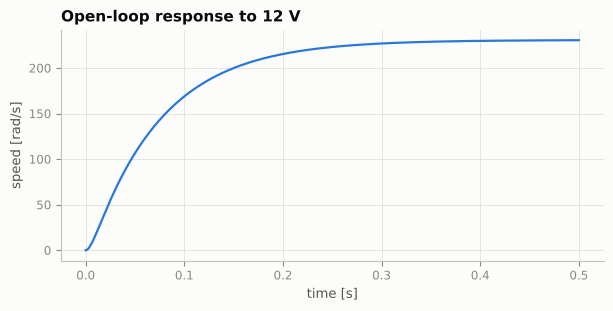

In [2]:
G = transfer_function(p)
print("poles [rad/s]:", np.round(np.real(ct.poles(G)), 2), "-> time constants [ms]:", np.round(-1000/np.real(ct.poles(G)), 1))
print("DC gain:", round(float(ct.dcgain(G)), 2), "rad/s per volt;  no-load speed at 12 V:", round(float(ct.dcgain(G))*12), "rad/s")
t = np.linspace(0, 0.5, 500); _, y = ct.step_response(G*12, t)
fig, ax = plt.subplots(figsize=(7,3)); ax.plot(t, y, color=style.BLUE); ax.set(xlabel="time [s]", ylabel="speed [rad/s]", title="Open-loop response to 12 V"); plt.show()

Both poles are real and stable, a fast electrical one (5 ms) and a slower mechanical one (72 ms), so the open-loop motor is a well-behaved second-order lag. Feedback is needed for accuracy and disturbance rejection, not for stability.

## 2. Design: same specification for both controllers

Task: 100 rad/s step, then a 0.02 N·m load step at 1 s. Both controllers are tuned by Nelder–Mead on **one shared cost** (ITAE of the step + load dip + recovery time) with the same penalties: overshoot ≤ 5 %, peak command ≤ 12 V, and (PID only) phase margin ≥ 60°.

* **PID**: derivative on the measurement through a first-order filter ($N=500$ rad/s), back-calculation anti-windup.
* **LQR + integral**: full state $[i,\omega,z]$, $\dot z = r-\omega$, weights $Q=\mathrm{diag}(0,q_\omega,q_z)$, $\rho=1$ searched in log-space.

In [3]:
pid, _ = tune_pid(p)
lqr, _ = tune_lqr(p)
print(f"PID  : Kp={pid.Kp:.4f}  Ki={pid.Ki:.3f}  Kd={pid.Kd:.2e}")
print(f"LQR  : Kx=[{lqr.Kx[0,0]:.3f} (i), {lqr.Kx[0,1]:.3f} (w)]  Kz={lqr.Kz:.2f}")

PID  : Kp=0.1187  Ki=2.111  Kd=5.22e-04
LQR  : Kx=[1.494 (i), 2.088 (w)]  Kz=-49.32


## 3. Step and load-disturbance response (noise-free)

,PID,LQR + integral
overshoot [%],4.934,0.000
10-90 % rise [s],0.051,0.083
2 % settling [s],0.202,0.154
ITAE,0.143,0.164
peak command [V],12.000,12.000
load dip [rad/s],1.794,0.465
load recovery [s],0.103,0.000
steady-state error [rad/s],0.000,0.000


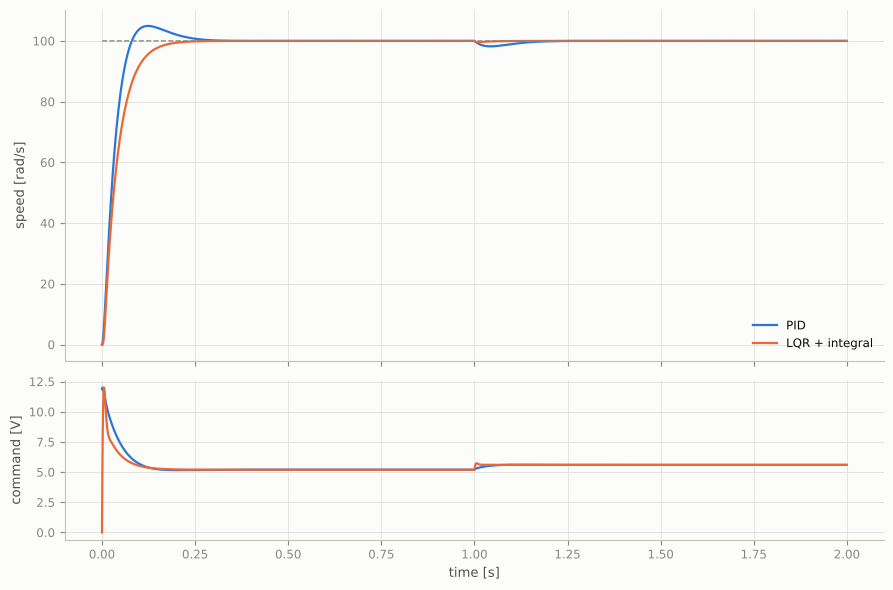

In [4]:
res = {"PID": simulate(pid, p), "LQR + integral": simulate(lqr, p)}
tab = pd.DataFrame({k: step_metrics(r) for k, r in res.items()}).round(3)
tab.index = ["overshoot [%]", "10-90 % rise [s]", "2 % settling [s]", "ITAE", "peak command [V]", "load dip [rad/s]", "load recovery [s]", "steady-state error [rad/s]"]
display(tab)

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw=dict(height_ratios=[2.2, 1]))
for (k, r), c in zip(res.items(), (style.BLUE, style.ORANGE)):
    ax[0].plot(r.t, r.w, color=c, label=k); ax[1].plot(r.t, r.u_cmd, color=c)
ax[0].plot(r.t, r.r, "--", color=style.REF, lw=1); ax[0].legend(); ax[0].set(ylabel="speed [rad/s]")
ax[1].set(ylabel="command [V]", xlabel="time [s]"); plt.tight_layout(); plt.show()

The LQR controller has no overshoot and rejects the load step about four times better (0.46 vs 1.8 rad/s dip), because it feeds back the armature **current**, which sees the torque disturbance before the speed does. The PID has the faster rise. **Caveat:** this is not a like-for-like information comparison. LQR uses a current measurement the PID does not have; section 6 removes that advantage.

## 4. Stability margins

In [5]:
L_pid = pid.tf() * G
L_lqr = lqr_loop_tf(lqr.Kx[0], lqr.Kz, p)
rows = {}
for name, L, wc_adj in (("PID", L_pid, None), ("LQR + integral (loop at plant input)", L_lqr, None)):
    m = loop_margins(L)
    rows[name] = dict(phase_margin_deg=m["phase_margin_deg"], crossover_rad_s=m["wcp"], gain_margin_dB=m["gain_margin_db"],
                      pm_after_half_sample_ZOH_delay_deg=m["phase_margin_deg"] - np.degrees(m["wcp"] * 1e-3 / 2))
display(pd.DataFrame(rows).T.round(1))

,phase_margin_deg,crossover_rad_s,gain_margin_dB,pm_after_half_sample_ZOH_delay_deg
PID,81.3,31.4,inf,80.4
LQR + integral (loop at plant input),73.5,358.2,inf,63.2


The margins are for the continuous-time loop. The last column subtracts the phase lag of the half-sample zero-order-hold delay at 1 kHz (about $\omega_c T_s/2$); it matters for the LQR loop, whose crossover is ten times higher.

## 5. Saturation and anti-windup (180 rad/s step, 12 V supply)

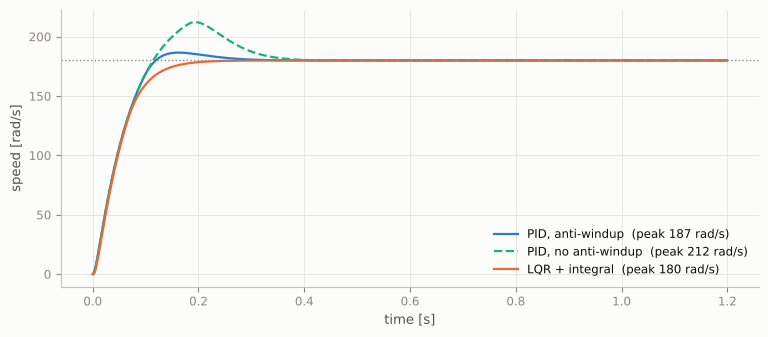

In [6]:
big = dict(r_fn=lambda t: 180.0, d_fn=lambda t: 0.0, T=1.2)
sims = {"PID, anti-windup": simulate(pid, p, **big),
        "PID, no anti-windup": simulate(PID(pid.Kp, pid.Ki, pid.Kd, antiwindup=False), p, **big),
        "LQR + integral": simulate(lqr, p, **big)}
fig, ax = plt.subplots(figsize=(9, 3.6))
for (k, r), (c, ls) in zip(sims.items(), ((style.BLUE, "-"), (style.AQUA, "--"), (style.ORANGE, "-"))):
    ax.plot(r.t, r.w, color=c, ls=ls, label=f"{k}  (peak {r.w.max():.0f} rad/s)")
ax.axhline(180, color=style.REF, ls=":", lw=1); ax.legend(loc="lower right"); ax.set(xlabel="time [s]", ylabel="speed [rad/s]"); plt.show()

## 6. Kalman filter: speed is the only measurement

The encoder reads $\omega$ with white noise $\sigma=2$ rad/s. The simulator also injects white noise on the voltage (0.1 V) and on the load torque (0.005 N·m) at every sample. The filter is told exactly these values, so any inconsistency is a bug, not model mismatch. Discrete model $x_{k+1}=A_dx_k+B_du_k+w_k$, $Q=[B_d\ B_{d,T}]\,\mathrm{diag}(\sigma_v^2,\sigma_T^2)\,[\cdot]^T$, Joseph-form covariance update.

In [7]:
NOISE = dict(sigma=2.0, sigma_v=0.1, sigma_T=0.005)
KF_KW = dict(sigma_meas=2.0, sigma_v=0.1, sigma_T=0.005)
mk_lqg = lambda three=False: LQRIntegral(lqr.Kx, lqr.Kz, estimator=motor_kf(p, disturbance_state=three, **KF_KW))

r = simulate(mk_lqg(), p, T=2.0, seed=3, **NOISE)
m = (r.t >= 0.05) & (r.t < 1.0)
rm = lambda a: float(np.sqrt(np.mean(np.square(a))))
print(f"speed error, raw encoder: {rm((r.y-r.w)[m]):.3f} rad/s   Kalman estimate: {rm((r.xhat[:,1]-r.w)[m]):.3f} rad/s")
print(f"current (never measured) estimate error: {rm((r.xhat[:,0]-r.i)[m]):.3f} A   vs. true current std {np.std(r.i[m]):.2f} A")

speed error, raw encoder: 1.999 rad/s   Kalman estimate: 0.175 rad/s
current (never measured) estimate error: 0.030 A   vs. true current std 0.44 A


**Is the filter consistent?** For a correct model the normalised innovation squared (NIS) has mean 1 and the innovations are white. Check on a 20 s run with no load step:

In [8]:
from scipy.stats import chi2
c = mk_lqg()
simulate(c, p, T=20.0, seed=11, d_fn=lambda t: 0.0, **NOISE)
nis = np.array(c.est.nis)[1000:]; nu = np.array(c.est.innov)[1000:] / np.sqrt(np.array(c.est.S)[1000:])
N = len(nis); lo, hi = chi2.ppf([0.025, 0.975], 1)
acf = [np.corrcoef(nu[:-l], nu[l:])[0, 1] for l in range(1, 31)]
print(f"mean NIS = {nis.mean():.3f}  (95 % band for the mean: {1-1.96*np.sqrt(2/N):.3f} to {1+1.96*np.sqrt(2/N):.3f}),  N = {N}")
print(f"{np.mean((nis>=lo)&(nis<=hi)):.1%} of NIS values inside the chi2(1) 95 % interval (expect 95 %)")
print(f"innovation autocorrelation lags 1-30: max |rho| = {np.max(np.abs(acf)):.4f}  (white-noise band ±{1.96/np.sqrt(N):.4f})")

mean NIS = 0.995  (95 % band for the mean: 0.980 to 1.020),  N = 19000
95.1% of NIS values inside the chi2(1) 95 % interval (expect 95 %)
innovation autocorrelation lags 1-30: max |rho| = 0.0142  (white-noise band ±0.0142)


## 7. Closed loop with noise: PID vs LQG (20 seeds)

In [9]:
rows = {"PID": [], "LQG (LQR + Kalman)": []}
for seed in range(20):
    for name, ctrl in (("PID", pid), ("LQG (LQR + Kalman)", mk_lqg())):
        r = simulate(ctrl, p, T=2.0, seed=seed, **NOISE); k = (r.t >= 0.5) & (r.t < 1.0)
        rows[name].append(dict(speed_err_rms=rm(r.w[k]-r.r[k]), voltage_std=np.std(r.u[k]), load_dip=np.max(r.r[r.t>=1]-r.w[r.t>=1])))
display(pd.DataFrame({n: pd.DataFrame(v).mean() for n, v in rows.items()}).round(3).rename(
    index={"speed_err_rms": "speed error RMS [rad/s]", "voltage_std": "voltage std [V]", "load_dip": "load dip [rad/s]"}))

,PID,LQG (LQR + Kalman)
speed error RMS [rad/s],0.276,0.283
voltage std [V],0.610,0.170
load dip [rad/s],2.107,2.166


Tracking accuracy and load dip are **statistically the same** (process noise dominates the speed error). The LQG controller needs about **3.6× less voltage activity** because it acts on the filtered estimate instead of raw encoder noise. That is the benefit: gentler actuation for the same performance. It is not better tracking.

## 8. Unknown load torque as a filter state

Adding a random-walk state $T_\ell$ lets the filter infer the load from the speed signal. Without it, the 2-state filter cannot explain why the current has to rise after the load step and its current estimate is biased.

In [10]:
sim = {k: simulate(mk_lqg(three), p, T=2.0, seed=5, **NOISE) for k, three in (("2-state", False), ("3-state", True))}
post = sim["3-state"].t >= 1.3
print("estimated torque after step:", round(float(sim["3-state"].xhat[post, 2].mean()), 4), "N·m (true 0.02)")
for k, r in sim.items():
    print(f"{k}: mean current-estimate error after step = {np.mean(r.xhat[post,0]-r.i[post]):+.3f} A")

estimated torque after step: 0.0201 N·m (true 0.02)
2-state: mean current-estimate error after step = -0.227 A
3-state: mean current-estimate error after step = +0.001 A


## 9. Same machinery on a daily physiological series

Model: $y_t=\mu_t+s_t+\varepsilon_t$ with $\mu_t$ a random-walk baseline and $s_t$ a weekly seasonal (dummy form, 6 states). For HRV, $y=\ln(\mathrm{HRV})$. Variances are estimated by **maximum likelihood** on the Kalman prediction-error decomposition; missing days are handled by skipping the update; the RTS smoother gives the baseline and weekday effects.

The cell below runs on **synthetic data with known ground truth**. To use your own WHOOP export, set `CSV` to its path (metric `hrv`, `recovery` or `rhr`).

SYNTHETIC DEMO DATA | estimated noise sd: 0.082 (log units)
                           Mon  Tue  Wed  Thu  Fri   Sat   Sun
weekday effect on HRV [%]  5.0  5.7 -1.9  0.4 -5.5 -15.1  13.9
true (synthetic)  : [2.0, 3.0, 1.0, 0.0, -3.0, -13.1, 11.6]
baseline RMSE: smoothed 0.027 vs raw observations 0.120 (log units)


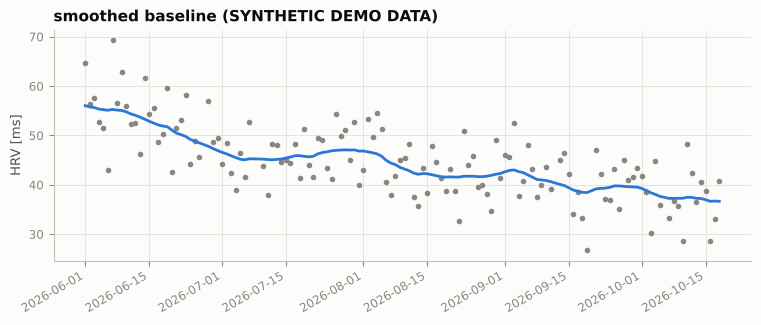

In [11]:
CSV, METRIC = None, "hrv"          # e.g. CSV = ROOT / "data" / "whoop.csv"
if CSV is None:
    df, truth = synthetic_hrv(); label = "SYNTHETIC DEMO DATA"
else:
    df, truth = load_whoop_csv(CSV, METRIC), None; label = "WHOOP export"
y = df["y"].to_numpy(float)
fit = fit_level_seasonal(y)
xs = fit["x_smooth"]; wd = np.array([d.weekday() for d in df.index])
eff = [xs[wd == k, 1].mean() for k in range(7)]
print(label, "| estimated noise sd:", round(float(np.sqrt(fit["params"]["var_obs"])), 3), "(log units)")
print(pd.Series([(np.exp(e) - 1) * 100 for e in eff], index=["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]).round(1).rename("weekday effect on HRV [%]").to_frame().T.to_string())
if truth is not None:
    print("true (synthetic)  :", [round(float((np.exp(truth[k]) - 1) * 100), 1) for k in range(7)])
    print(f"baseline RMSE: smoothed {np.sqrt(np.mean((xs[:,0]-df['level_true'])**2)):.3f} vs raw observations {np.sqrt(np.nanmean((y-df['level_true'])**2)):.3f} (log units)")
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(df.index, np.exp(y), ".", color=style.MUTED); ax.plot(df.index, np.exp(xs[:,0]), color=style.BLUE, lw=2)
ax.set(title=f"smoothed baseline ({label})", ylabel="HRV [ms]"); fig.autofmt_xdate(); plt.show()

## 10. Limits of this work

* The motor is a **linear model plus voltage saturation**; there is no Coulomb friction, no encoder quantisation, no PWM or current limit, and the controller runs with zero computation delay at 1 kHz.
* PID and LQR are compared on a *tuned-to-the-same-cost* basis, but the optimiser finds local minima (Nelder–Mead) and the PID sits on its overshoot and voltage constraints.
* The Kalman-filter consistency result holds because the filter was given the true noise levels. With wrong covariances it would still run, but the NIS test would reveal it.
* The WHOOP cell shows the method on synthetic data. Conclusions about a real person need the real export.